# 01 Exploration: What makes a California home expensive?

**Data:** 8 months of CRMLS sold listings (Oct 2025 – May 2026)  
**Target:** `ClosePrice`, the final sale price  
**Scope:** single-family homes only (`PropertyType = Residential`, `PropertySubType = SingleFamilyResidence`)

Before building a model, I want to understand what actually moves price. This notebook goes through it like a story:

1. Meet the data
2. The typical California home
3. The 5 key features (price, size, beds, baths, lot)
4. Cleaning the weird values
5. Size and price
6. The bedroom paradox
7. Location, location, location
8. Bidding wars
9. Old homes cost more per sq ft
10. Spring is selling season
11. Myths: pools and views
12. What this means for the model

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.0f}".format
plt.rcParams["figure.figsize"] = (9, 5)

## 1. Meet the data
I combined all 8 monthly files and kept only single-family homes, as the task doc says.

In [2]:
files = sorted(glob.glob("CRMLSSold*.csv"))
raw = pd.concat([pd.read_csv(f, low_memory=False) for f in files])
print("All listings:", raw.shape)

df = raw[(raw["PropertyType"] == "Residential") & (raw["PropertySubType"] == "SingleFamilyResidence")]
df = df.drop_duplicates("ListingKey")
print("Single-family homes:", df.shape)

df["CloseDate"] = pd.to_datetime(df["CloseDate"])
df["CloseMonth"] = df["CloseDate"].dt.to_period("M")

All listings: (166725, 78)
Single-family homes: (83435, 78)


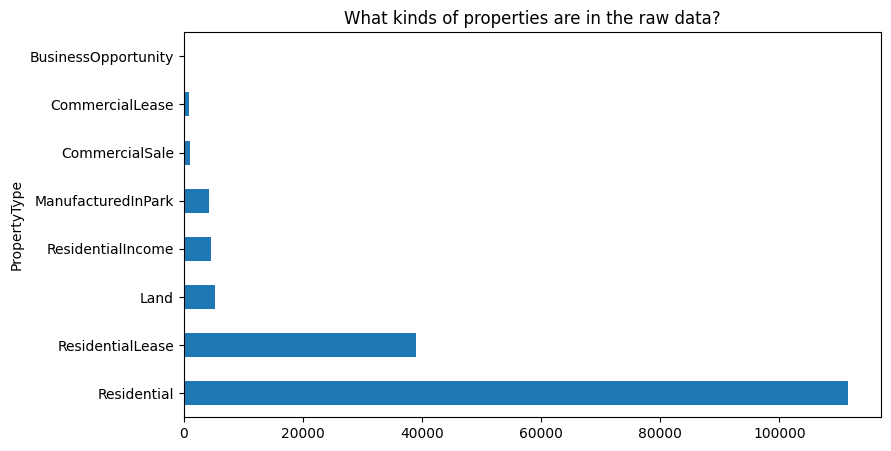

In [3]:
raw["PropertyType"].value_counts().plot.barh()
plt.title("What kinds of properties are in the raw data?")
plt.show()

> **What this tells us:** About half the raw data is single-family homes. The rest is rentals, land and commercial, which would confuse a price model, so filtering is the right first step.

## 2. The typical California home
The median is better than the mean here because a few mansions pull the average way up.

In [4]:
cols = ["ClosePrice", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt"]
typical = df[cols].median().to_frame("Median home")
typical.loc["Mean ClosePrice"] = df["ClosePrice"].mean()
typical.astype(int)

,Median home
ClosePrice,890000
LivingArea,1824
BedroomsTotal,3
BathroomsTotalInteger,2
LotSizeSquareFeet,7260
YearBuilt,1976
Mean ClosePrice,1339487


> **What this tells us:** The typical home sold is a **3 bed / 2 bath, ~1,800 sq ft house on a ~7,300 sq ft lot, built around 1976, for ~$890K**. The mean price is about $1.34M, much higher than the median, which is our first hint that price is skewed.

## 3. The 5 key features

In [5]:
feats = ["ClosePrice", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet"]
df[feats].describe()

,ClosePrice,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet
count,"83,435","83,396","83,435","83,434","81,993"
mean,"1,339,487","2,054",3,3,"488,355"
std,"7,666,771","1,038",1,1,"20,482,100"
min,2,0,0,0,0
25%,"620,000","1,388",3,2,"5,663"
50%,"890,000","1,824",3,2,"7,260"
75%,"1,415,000","2,450",4,3,"10,454"
max,"989,500,000","31,068",22,23,"1,938,942,720"


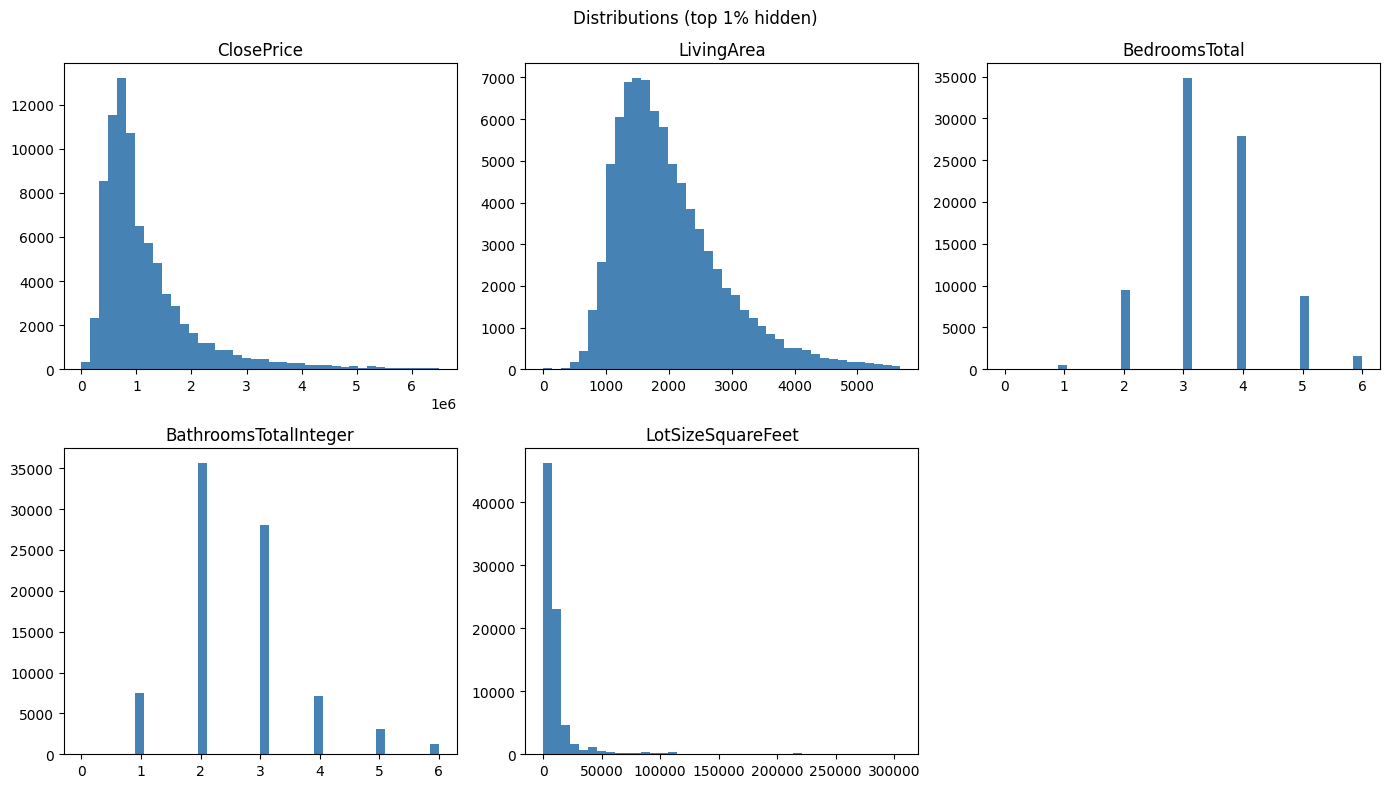

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.flat, feats):
    s = df[c].dropna()
    s = s[s <= s.quantile(0.99)]       # hide the top 1% so we can see the shape
    ax.hist(s, bins=40, color="steelblue")
    ax.set_title(c)
axes.flat[-1].axis("off")
plt.suptitle("Distributions (top 1% hidden)")
plt.tight_layout()
plt.show()

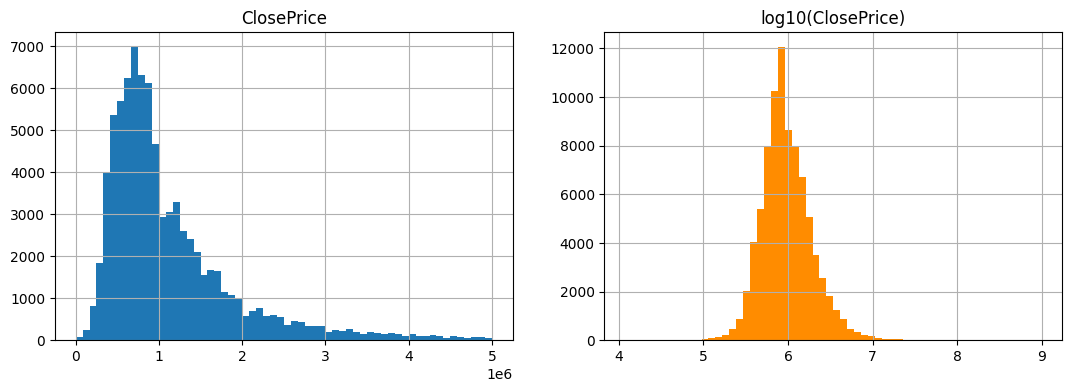

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df[df["ClosePrice"] < 5_000_000]["ClosePrice"].hist(bins=60, ax=axes[0])
axes[0].set_title("ClosePrice")
np.log10(df[df["ClosePrice"] > 10_000]["ClosePrice"]).hist(bins=60, ax=axes[1], color="darkorange")
axes[1].set_title("log10(ClosePrice)")
plt.show()

> **What this tells us:**
> - **Price** has a long right tail: lots of homes around $600K–$1.4M and a few very expensive ones. Taking the **log** turns it into a nice bell shape, so predicting log price will probably work better.
> - **LivingArea** is also right-skewed, centered around 1,500–2,500 sq ft.
> - **Bedrooms and bathrooms** are mostly 3–4 beds and 2–3 baths.
> - **LotSize** has the most extreme tail (some lots are farms or ranches).

## 4. Cleaning the weird values
Some rows clearly aren't normal home sales.

In [8]:
checks = pd.Series({
    "Price under $50K": (df["ClosePrice"] < 50_000).sum(),
    "Price over $20M": (df["ClosePrice"] > 20_000_000).sum(),
    "LivingArea under 300 sq ft": (df["LivingArea"] < 300).sum(),
    "0 bedrooms": (df["BedroomsTotal"] == 0).sum(),
}, name="rows")
print(checks)
print("\nCheapest:", df["ClosePrice"].min(), " Most expensive:", df["ClosePrice"].max())

Price under $50K              30
Price over $20M               64
LivingArea under 300 sq ft    32
0 bedrooms                    42
Name: rows, dtype: int64

Cheapest: 1.75  Most expensive: 989500000.0


In [9]:
clean = df[(df["ClosePrice"] >= 50_000) & (df["ClosePrice"] <= 20_000_000) & (df["LivingArea"] >= 300)].copy()
clean["PricePerSqFt"] = clean["ClosePrice"] / clean["LivingArea"]
print(f"Kept {len(clean):,} of {len(df):,} rows ({len(clean)/len(df):.1%})")

Kept 83,274 of 83,435 rows (99.8%)


> **What this tells us:** A home that "sold" for **$1.75** or **$989 million** is a typo or not a real sale. Removing a small number of rows (under 0.2%) gives cleaner data for everything below.
>
> I also made a new column, **price per square foot**. It lets us compare a small home and a big home fairly, so I'll use it a lot in the rest of the story.

## 5. Size and price

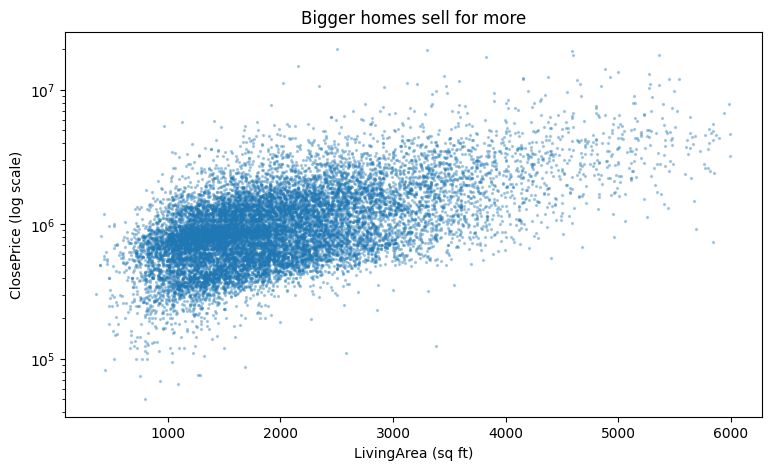

Spearman correlation: 0.52


In [10]:
s = clean[clean["LivingArea"] < 6000].sample(15000, random_state=1)
plt.scatter(s["LivingArea"], s["ClosePrice"], s=2, alpha=0.3)
plt.yscale("log")
plt.title("Bigger homes sell for more")
plt.xlabel("LivingArea (sq ft)")
plt.ylabel("ClosePrice (log scale)")
plt.show()

print("Spearman correlation:", round(clean["LivingArea"].rank().corr(clean["ClosePrice"].rank()), 2))

> **What this tells us:** Bigger homes clearly sell for more (correlation ≈ 0.5), but the cloud is very wide. Two 2,000 sq ft homes can differ in price by millions. **Size alone isn't enough**, so something else is going on. (Spoiler: location.)

## 6. The bedroom paradox
More bedrooms means a higher price. But is each square foot worth more?

In [11]:
beds = (clean[clean["BedroomsTotal"].between(1, 6)]
        .groupby("BedroomsTotal")
        .agg(homes=("ClosePrice", "size"),
             median_price=("ClosePrice", "median"),
             median_sqft=("LivingArea", "median"),
             price_per_sqft=("PricePerSqFt", "median")))
beds

,homes,median_price,median_sqft,price_per_sqft
BedroomsTotal,,,,
1,488,"437,500",686,628
2,9403,"635,000","1,113",569
3,34802,"815,000","1,554",546
4,27885,"1,030,000","2,191",503
5,8708,"1,365,000","3,017",483
6,1543,"1,750,000","3,672",524


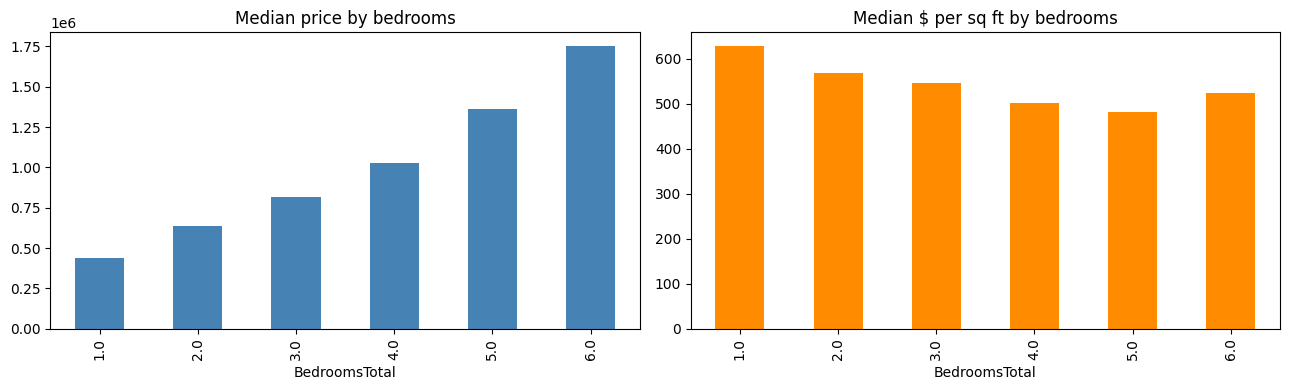

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
beds["median_price"].plot.bar(ax=axes[0], color="steelblue", title="Median price by bedrooms")
beds["price_per_sqft"].plot.bar(ax=axes[1], color="darkorange", title="Median $ per sq ft by bedrooms")
plt.tight_layout()
plt.show()

> **What this tells us:** Total price goes up with every bedroom (2 beds ≈ \$635K → 5 beds ≈ \$1.37M). But **price per square foot goes down**, from about \$570/sq ft for 2-bed homes to about \$480 for 5-bed homes. Big 4–5 bedroom homes are often in cheaper suburbs and inland areas where land is cheaper.
>
> So bedrooms matter, but **partly because they're a stand-in for size and location**.

## 7. Location, location, location

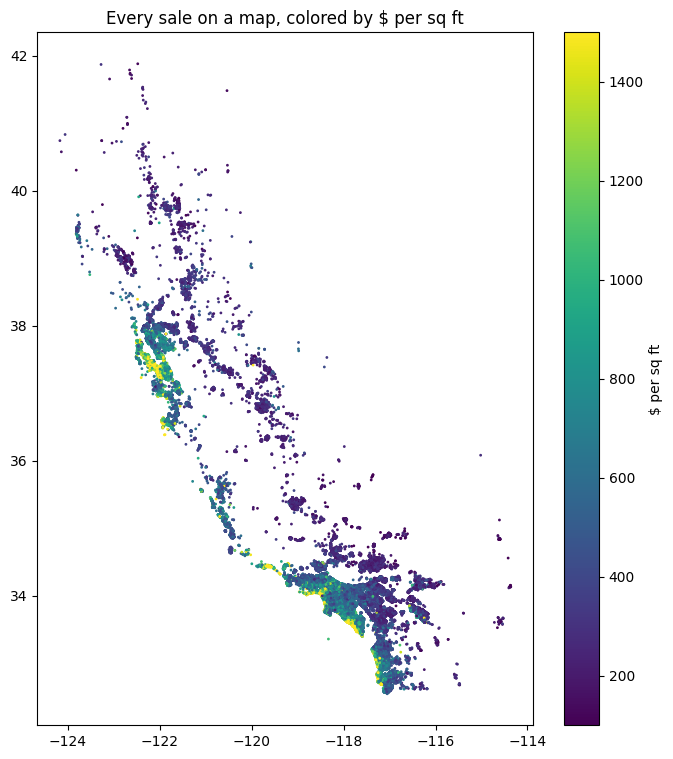

In [13]:
geo = clean[clean["Latitude"].between(32, 42.1) & clean["Longitude"].between(-124.5, -114)]
plt.figure(figsize=(8, 9))
plt.scatter(geo["Longitude"], geo["Latitude"], c=geo["PricePerSqFt"].clip(100, 1500), s=1, cmap="viridis")
plt.colorbar(label="$ per sq ft")
plt.title("Every sale on a map, colored by $ per sq ft")
plt.show()

In [14]:
county = (clean.groupby("CountyOrParish")
          .agg(homes=("ClosePrice", "size"),
               median_price=("ClosePrice", "median"),
               price_per_sqft=("PricePerSqFt", "median"))
          .query("homes >= 300"))
county["sqft_for_$1M"] = 1_000_000 / county["price_per_sqft"]
county = county.sort_values("sqft_for_$1M")
county

,homes,median_price,price_per_sqft,sqft_for_$1M
CountyOrParish,,,,
San Mateo,1186,"2,105,000","1,201",832
Santa Clara,2355,"1,880,000","1,085",922
Santa Cruz,515,"1,305,000",735,"1,360"
Alameda,3865,"1,300,000",731,"1,369"
Orange,8011,"1,405,000",720,"1,389"
Los Angeles,20579,"1,000,000",632,"1,582"
San Diego,9188,"1,060,000",600,"1,667"
Monterey,909,"949,000",591,"1,693"
San Luis Obispo,1403,"945,000",553,"1,809"


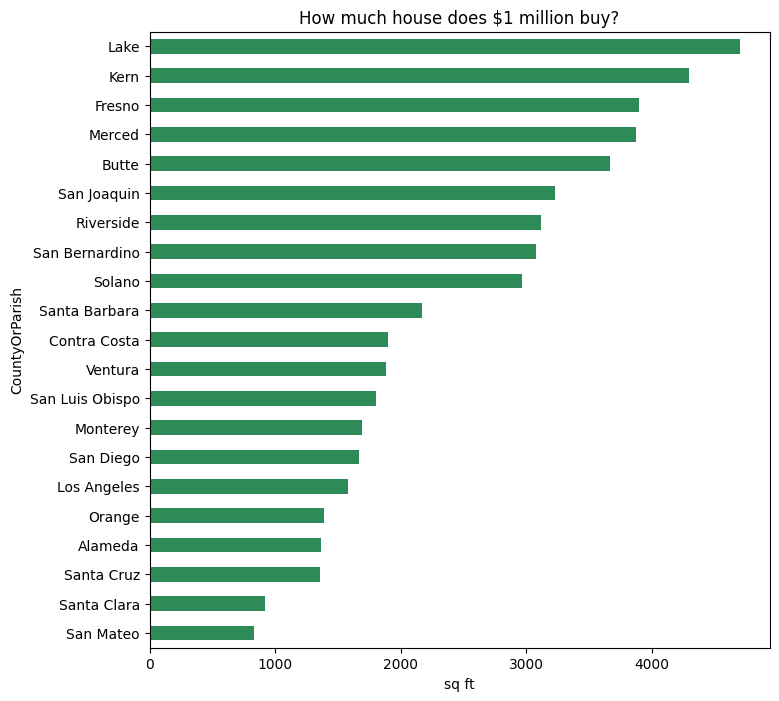

In [15]:
county["sqft_for_$1M"].plot.barh(figsize=(8, 8), color="seagreen")
plt.title("How much house does $1 million buy?")
plt.xlabel("sq ft")
plt.show()

> **What this tells us:** The map lights up along the coast, especially the **Bay Area** and **coastal LA/Orange County**.
>
> The "$1 million" chart is the most striking result: **$1M buys about 830 sq ft in San Mateo but about 4,700 sq ft in Lake County**, almost **6× more house** for the same money.
>
> This explains the wide cloud in Section 5: a 2,000 sq ft home in San Mateo and one in Kern are completely different prices. **Location has to be in the model** (county, zip code, latitude/longitude, and the school districts in Week 6).

## 8. Bidding wars
How often do homes sell for **more** than the asking price?

Overall: 39% of homes sold above asking


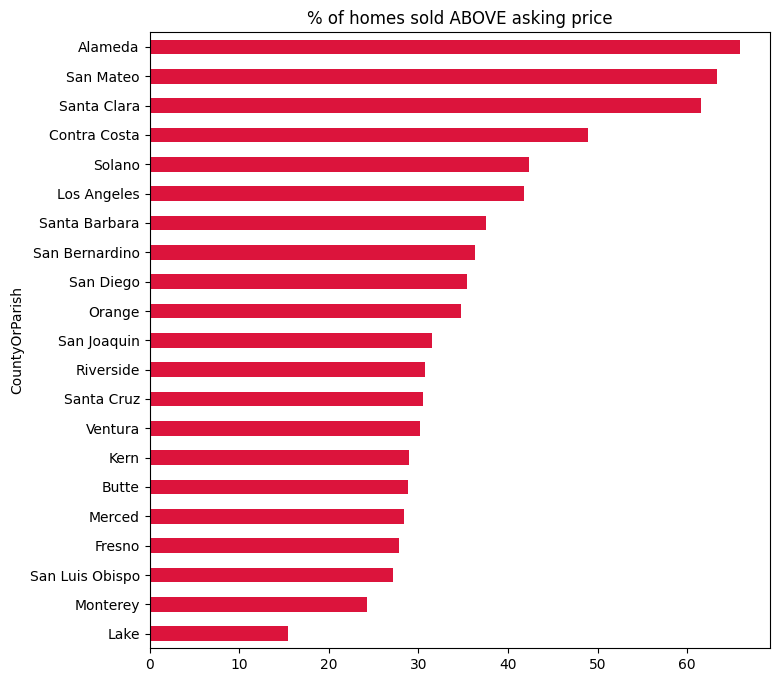

In [16]:
clean["SoldAboveList"] = clean["ClosePrice"] > clean["ListPrice"]
print(f"Overall: {clean['SoldAboveList'].mean():.0%} of homes sold above asking")

war = clean.groupby("CountyOrParish")["SoldAboveList"].agg(["mean", "size"]).query("size >= 300")["mean"].sort_values()
(war * 100).plot.barh(figsize=(8, 8), color="crimson")
plt.title("% of homes sold ABOVE asking price")
plt.show()

> **What this tells us:** About **39%** of homes sold above asking. In the Bay Area (**Alameda, Santa Clara, San Mateo**), it's over **60%**, so most homes there end up in a bidding war. In Monterey or Lake County it's closer to 15–25%.
>
> This is also a warning: `ListPrice` is very close to `ClosePrice`, so if we use it as a feature, the model is basically "cheating". **The team should decide whether ListPrice is allowed.**

## 9. Old homes cost more per square foot

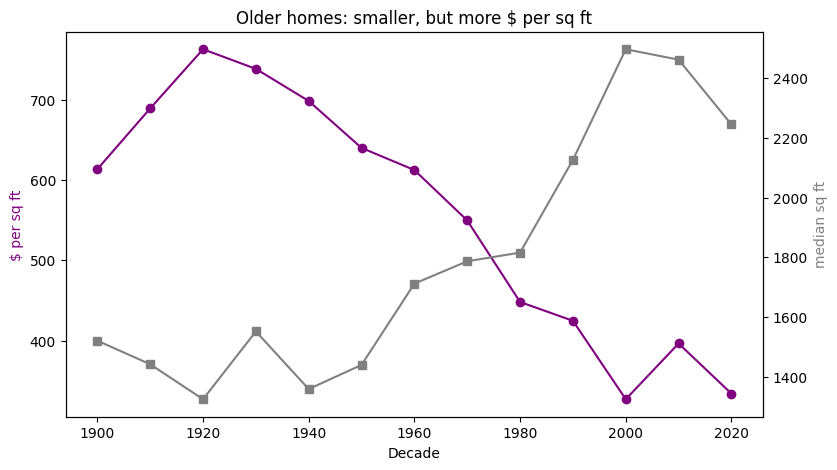

,homes,price_per_sqft,median_sqft
Decade,,,
1900,522,614,"1,521"
1910,930,689,"1,442"
1920,3466,763,"1,325"
1930,2117,738,"1,552"
1940,5215,698,"1,359"
1950,12944,640,"1,440"
1960,10270,612,"1,712"
1970,9869,550,"1,787"
1980,10101,448,"1,816"


In [17]:
clean["Decade"] = (clean["YearBuilt"] // 10 * 10).astype("Int64")
dec = clean[clean["Decade"] >= 1900].groupby("Decade").agg(
    homes=("ClosePrice", "size"),
    price_per_sqft=("PricePerSqFt", "median"),
    median_sqft=("LivingArea", "median"))

fig, ax1 = plt.subplots()
dec["price_per_sqft"].plot(ax=ax1, marker="o", color="purple")
ax1.set_ylabel("$ per sq ft", color="purple")
ax2 = ax1.twinx()
dec["median_sqft"].plot(ax=ax2, marker="s", color="gray")
ax2.set_ylabel("median sq ft", color="gray")
plt.title("Older homes: smaller, but more $ per sq ft")
plt.show()
dec

> **What this tells us:** You'd expect newer homes to be worth more, but it's the opposite. **1920s homes sell for about \$760/sq ft, while 2000s homes sell for about \$330/sq ft.**
>
> The reason is that old homes were built in the original, central, coastal cities, while new homes are built where there's still empty land (inland). Newer homes are also bigger (≈2,500 vs ≈1,300 sq ft).
>
> **Lesson:** YearBuilt is mostly telling us about **location**, not quality. The model needs location features so it doesn't learn the wrong thing.

## 10. Spring is selling season

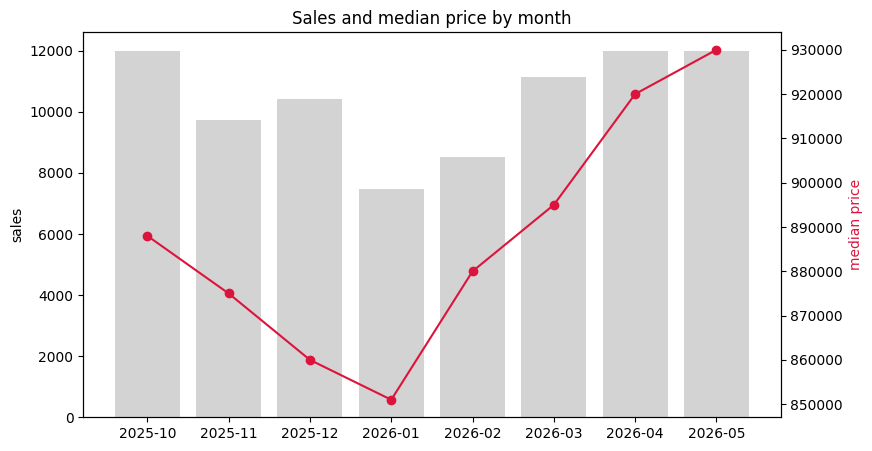

,sales,median_price,pct_above_list
CloseMonth,,,
2025-10,12003,"888,000",36
2025-11,9717,"875,000",36
2025-12,10424,"860,000",34
2026-01,7459,"851,000",32
2026-02,8530,"880,000",38
2026-03,11149,"895,000",42
2026-04,12000,"920,000",43
2026-05,11992,"930,000",44


In [18]:
month = clean.groupby("CloseMonth").agg(
    sales=("ClosePrice", "size"),
    median_price=("ClosePrice", "median"),
    pct_above_list=("SoldAboveList", "mean"))
month = month[month["sales"] > 100]
month["pct_above_list"] *= 100

fig, ax1 = plt.subplots()
ax1.bar(month.index.astype(str), month["sales"], color="lightgray")
ax1.set_ylabel("sales")
ax2 = ax1.twinx()
ax2.plot(month.index.astype(str), month["median_price"], color="crimson", marker="o")
ax2.set_ylabel("median price", color="crimson")
plt.title("Sales and median price by month")
plt.show()
month

> **What this tells us:** The market slows down in winter. **January** had the fewest sales and the lowest median price (≈\$851K). By **May**, prices were up to ≈\$930K, about 9% higher, and the share selling above asking went from about 32% to 44%.
>
> This matters for Week 3: we test on the **most recent month**, so the model needs to handle the market moving over time.

## 11. Myths: pools and views

In [19]:
for col in ["PoolPrivateYN", "ViewYN"]:
    print(clean.groupby(col)["PricePerSqFt"].median().rename(f"$ per sq ft by {col}"), "\n")

PoolPrivateYN
False   508
True    505
Name: $ per sq ft by PoolPrivateYN, dtype: float64 

ViewYN
False   557
True    495
Name: $ per sq ft by ViewYN, dtype: float64 



> **What this tells us:** Surprisingly, homes **with a pool or a view don't sell for more per square foot**. Homes with a view are actually a bit lower.
>
> Same story as Section 9: pools are common in hot, inland, cheaper areas, and "view" can mean mountains in the desert. These features may still help **once location is controlled for**, but on their own they're misleading.

## 12. Correlation summary

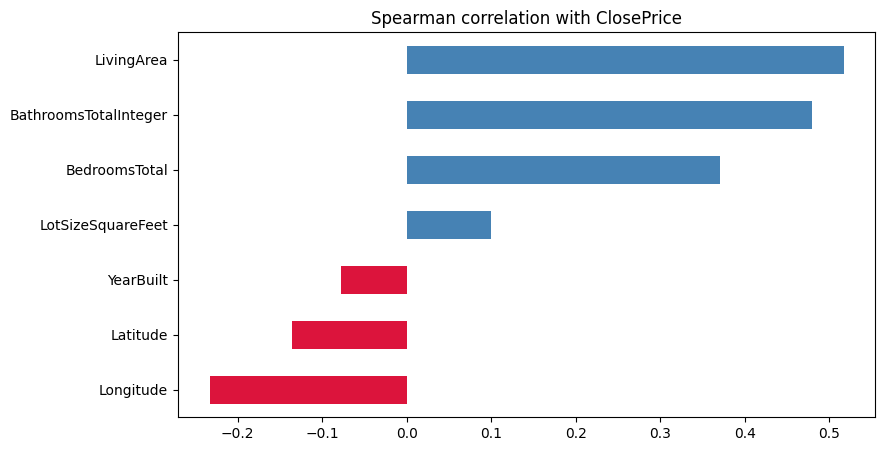

Longitude                -0.23
Latitude                 -0.14
YearBuilt                -0.08
LotSizeSquareFeet         0.10
BedroomsTotal             0.37
BathroomsTotalInteger     0.48
LivingArea                0.52
Name: ClosePrice, dtype: object

In [20]:
num = ["ClosePrice", "LivingArea", "BathroomsTotalInteger", "BedroomsTotal", "LotSizeSquareFeet", "YearBuilt", "Latitude", "Longitude"]
corr = clean[num].rank().corr()["ClosePrice"].drop("ClosePrice").sort_values()   # Spearman
corr.plot.barh(color=["crimson" if v < 0 else "steelblue" for v in corr])
plt.title("Spearman correlation with ClosePrice")
plt.show()
corr.map("{:.2f}".format)

## The story in one paragraph

The typical California home sold for about **$890K**: a 3-bed, 2-bath, 1,800 sq ft house. **Size** is the strongest single feature, but **location dominates everything else**: the same $1M buys almost 6× more house in Lake County than in San Mateo. That one fact explains three surprising patterns: why **bigger-bedroom homes cost less per sq ft**, why **older homes cost more per sq ft**, and why **pools and views don't seem to add value**. The market is also **competitive** (39% sold above asking, 60%+ in the Bay Area) and **seasonal** (prices about 9% higher in May than January).

## What this means for the model (Week 3+)
1. **Remove** obviously bad prices and tiny living areas.
2. **Predict log(ClosePrice)** because price is very skewed.
3. **Location features are a must:** county, zip code, latitude/longitude, and later school districts.
4. **Decide as a team** whether `ListPrice` is allowed (leakage risk).
5. The market changes month to month, so the time-based train/test split matters.

## Questions for the team
- Can we use ListPrice?
- What price cut-offs should we use for outliers?
- Should we predict price or price per sq ft?